# Supplementary EDA — Online Shoppers Purchasing Intention

Training-only, five targeted investigations from PRD §5.1. This supplementary notebook is not submitted and does not fit or score models. It reconstructs the fixed row split for provenance, then discards holdout rows before predictor analysis.

## 1. Data quality, provenance and split

**Purpose.** Verify data quality and the duplicate-session description, then preserve row provenance. **Method.** Check schema, types, missingness, duplicates and balance before a deterministic stratified 80/20 split. **Implication.** Retain every row; all later analysis uses training rows only.

In [1]:
from pathlib import Path
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from IPython.display import display
SEED=42; TARGET='Revenue'
NOMINAL=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
NUMERIC=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
path=next((p for p in [Path('data/uci_468.csv'),Path('../data/uci_468.csv')] if p.is_file()),None)
if path is None: raise FileNotFoundError('Run from repository root or supplementary/: expected data/uci_468.csv')
raw=pd.read_csv(path); raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
source_hash=hashlib.sha256(path.read_bytes()).hexdigest()
if raw.shape!=(12330,19): raise ValueError(f'Unexpected shape including row ID: {raw.shape}')
if set(raw.columns)-{'_row_id'} != set(NUMERIC+NOMINAL+['Weekend',TARGET]): raise ValueError('Unexpected columns')
if raw[TARGET].isna().any() or not set(raw[TARGET].unique())<= {0,1}: raise ValueError('Revenue must be complete binary 0/1')
if raw[NUMERIC+['Weekend']].isna().any().any() or not np.isfinite(raw[NUMERIC+['Weekend']].to_numpy(float)).all(): raise ValueError('Numeric columns must be complete finite')
blank=raw[NOMINAL].astype('string').apply(lambda s:s.str.strip().eq('').sum()).reindex(raw.columns,fill_value=0)
quality=pd.DataFrame({'dtype':raw.drop(columns='_row_id').dtypes.astype(str),'missing':raw.drop(columns='_row_id').isna().sum(),'blank nominal':blank.drop(labels=['_row_id'],errors='ignore'),'unique':raw.drop(columns='_row_id').nunique()})
print('Shape (source rows, columns):',(len(raw),len(raw.columns)-1),'SHA-256:',source_hash)
print('Duplicate excess / unique full rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()),'/',raw.drop(columns='_row_id').drop_duplicates().shape[0])
display(quality); display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))
dup=raw.loc[raw.duplicated(subset=raw.columns.drop('_row_id'),keep='first')]
print('Excess duplicate rows:',len(dup),'Revenue counts:',dup[TARGET].value_counts().sort_index().to_dict())
display(pd.DataFrame({'duplicate median':dup[ACTIVITY].median(),'source median':raw[ACTIVITY].median(),'duplicate zero share':dup[ACTIVITY].eq(0).mean(),'source zero share':raw[ACTIVITY].eq(0).mean()}))
print('Duplicate rows are retained. Matching features do not identify the same visitor or session.')
print('Verified quality description: duplicate Revenue is entirely zero; medians/zero shares above show these repeated rows have very little activity relative to the full source.')
all_ids=raw._row_id.to_numpy(); y_all=raw[TARGET].to_numpy(int)
train_ids,test_ids=train_test_split(all_ids,test_size=.20,stratify=y_all,random_state=SEED)
ROOT=path.parent.parent if path.parent.name=='data' else path.parent.parent
ARTIFACTS=ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
pd.DataFrame({'row_id':np.sort(train_ids),'partition':'train'}).to_csv(ARTIFACTS/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':np.sort(test_ids),'partition':'test'}).to_csv(ARTIFACTS/'test_row_ids.csv',index=False)
X=raw.set_index('_row_id').loc[np.sort(train_ids)].copy(); y=X.pop(TARGET).astype(int)
X['Weekend']=X['Weekend'].astype(int)
del raw,dup,y_all,all_ids
fold_rows=[]
for fold,(fit,val) in enumerate(StratifiedKFold(5,shuffle=True,random_state=SEED).split(np.zeros(len(y)),y),1):
    ids=X.index.to_numpy(); fold_rows += [{'row_id':int(ids[i]),'fold':fold,'role':'fit'} for i in fit]+[{'row_id':int(ids[i]),'fold':fold,'role':'validation'} for i in val]
pd.DataFrame(fold_rows).to_csv(ARTIFACTS/'cv_fold_row_ids.csv',index=False)
print(f'Training rows retained: {len(X):,}; buyers={y.sum():,} ({y.mean():.2%}); holdout IDs recorded={len(test_ids):,} and holdout data discarded.')

Shape (source rows, columns): (12330, 18) SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Duplicate excess / unique full rows: 125 / 12205


,dtype,missing,blank nominal,unique
Administrative,int64,0,0,27
Administrative_Duration,float64,0,0,3335
Informational,int64,0,0,17
Informational_Duration,float64,0,0,1258
ProductRelated,int64,0,0,311
ProductRelated_Duration,float64,0,0,9551
BounceRates,float64,0,0,1872
ExitRates,float64,0,0,4777
PageValues,float64,0,0,2704
SpecialDay,float64,0,0,6


,sessions,share
Revenue,,
False,10422,0.845255
True,1908,0.154745


Excess duplicate rows: 125 Revenue counts: {False: 125}


,duplicate median,source median,duplicate zero share,source zero share
Administrative,0.0,1.000000,1.0,0.467802
Administrative_Duration,0.0,7.500000,1.0,0.478751
Informational,0.0,0.000000,1.0,0.786618
Informational_Duration,0.0,0.000000,1.0,0.804947
ProductRelated,1.0,18.000000,0.0,0.003082
ProductRelated_Duration,0.0,598.936905,1.0,0.061233


Duplicate rows are retained. Matching features do not identify the same visitor or session.
Verified quality description: duplicate Revenue is entirely zero; medians/zero shares above show these repeated rows have very little activity relative to the full source.
Training rows retained: 9,864; buyers=1,526 (15.47%); holdout IDs recorded=2,466 and holdout data discarded.


## 2. Zero versus positive activity and intensity

**Purpose.** Distinguish no activity from positive intensity and inspect skew, particularly for informational and administrative variables. **Method.** Show training zero/positive counts and buyer rates, positive quantiles and positive-value quantile bins that preserve tied values. **Implication.** Contrasts can motivate candidate presence/intensity representations but cannot establish predictive improvement.

In [2]:
rows=[]; details=[]
for col in ACTIVITY:
    pos=X[col]>0; rows.append({'feature':col,'skew':X[col].skew(),'zero_share':(~pos).mean(),'zero_n':(~pos).sum(),'zero_buyer_rate':y[~pos].mean(),'positive_n':pos.sum(),'positive_buyer_rate':y[pos].mean()})
    vals=X.loc[pos,col]
    for q,v in vals.quantile([.25,.5,.75,.9]).items(): details.append({'feature':col,'evidence':'positive quantile','level':q,'value':v})
    bins=pd.qcut(vals,4,duplicates='drop')
    t=pd.DataFrame({'bin':bins,'x':vals,'buyer':y[pos]}).groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyer_rate=('buyer','mean'))
    for b,r in t.iterrows(): details.append({'feature':col,'evidence':'positive intensity bin','level':str(b),'n':int(r.n),'value':r.mean_x,'buyer_rate':r.buyer_rate})
ACTIVITY_SUMMARY=pd.DataFrame(rows).set_index('feature'); display(ACTIVITY_SUMMARY.round(4)); display(pd.DataFrame(details).round(4))
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration']:
    r=ACTIVITY_SUMMARY.loc[col]
    print(f"{col}: skew={r['skew']:.2f}, zero={r['zero_share']:.1%}; buyer rate is {r['zero_buyer_rate']:.1%} at zero and {r['positive_buyer_rate']:.1%} above zero.")
eligible=ACTIVITY_SUMMARY[(ACTIVITY_SUMMARY['skew'].abs()>2)&(ACTIVITY_SUMMARY['zero_share']>=.50)].index.tolist()
print('Under the predeclared training EDA rule (|skew|>2 and zero share >=50%), candidate activity columns for fold-fitted presence indicators:', eligible or 'none')
print('Positive-only bins are broadly increasing for Informational and ProductRelated_Duration, but Administrative_Duration is uneven; bins are descriptive and do not establish conditional effects.')

,skew,zero_share,zero_n,zero_buyer_rate,positive_n,positive_buyer_rate
feature,,,,,,
Administrative,1.9668,0.4671,4607,0.0873,5257,0.2138
Administrative_Duration,5.6787,0.4771,4706,0.0901,5158,0.2136
Informational,4.1424,0.7854,7747,0.1330,2117,0.2343
Informational_Duration,7.7018,0.8047,7938,0.1349,1926,0.2362
ProductRelated,4.3718,0.0027,27,0.0741,9837,0.1549
ProductRelated_Duration,8.0091,0.0620,612,0.0131,9252,0.1641


,feature,evidence,level,value,n,buyer_rate
0,Administrative,positive quantile,0.25,2.0000,NaN,NaN
1,Administrative,positive quantile,0.5,3.0000,NaN,NaN
2,Administrative,positive quantile,0.75,6.0000,NaN,NaN
3,Administrative,positive quantile,0.9,9.0000,NaN,NaN
4,Administrative,positive intensity bin,"(0.999, 2.0]",1.4501,1962.0,0.2023
5,Administrative,positive intensity bin,"(2.0, 3.0]",3.0000,732.0,0.1858
6,Administrative,positive intensity bin,"(3.0, 6.0]",4.8148,1458.0,0.2181
7,Administrative,positive intensity bin,"(6.0, 27.0]",9.7738,1105.0,0.2471
8,Administrative_Duration,positive quantile,0.25,39.3250,NaN,NaN
9,Administrative_Duration,positive quantile,0.5,87.7250,NaN,NaN


Informational: skew=4.14, zero=78.5%; buyer rate is 13.3% at zero and 23.4% above zero.
Informational_Duration: skew=7.70, zero=80.5%; buyer rate is 13.5% at zero and 23.6% above zero.
Administrative: skew=1.97, zero=46.7%; buyer rate is 8.7% at zero and 21.4% above zero.
Administrative_Duration: skew=5.68, zero=47.7%; buyer rate is 9.0% at zero and 21.4% above zero.
Under the predeclared training EDA rule (|skew|>2 and zero share >=50%), candidate activity columns for fold-fitted presence indicators: ['Informational', 'Informational_Duration']
Positive-only bins are broadly increasing for Informational and ProductRelated_Duration, but Administrative_Duration is uneven; bins are descriptive and do not establish conditional effects.


## 3. VisitorType × Month support

**Purpose.** Check whether buyer-rate patterns vary across visitor type and month, and whether cells have enough support. **Method.** Display counts and rates for every observed cross-cell. **Implication.** Sparse cells caution against an interaction claim; rates are descriptive, not causal.

Month,Aug,Dec,Feb,Jul,June,Mar,May,Nov,Oct,Sep
VisitorType,,,,,,,,,,
New_Visitor,56,268,1,40,22,183,254,326,105,92
Other,0,54,0,0,0,0,0,20,0,0
Returning_Visitor,286,1069,145,304,206,1355,2449,2014,339,276


Month,Aug,Dec,Feb,Jul,June,Mar,May,Nov,Oct,Sep
VisitorType,,,,,,,,,,
New_Visitor,0.321,0.231,0.000,0.150,0.227,0.137,0.264,0.307,0.229,0.283
Other,NaN,0.204,NaN,NaN,NaN,NaN,NaN,0.100,NaN,NaN
Returning_Visitor,0.150,0.104,0.014,0.132,0.087,0.099,0.092,0.240,0.218,0.178


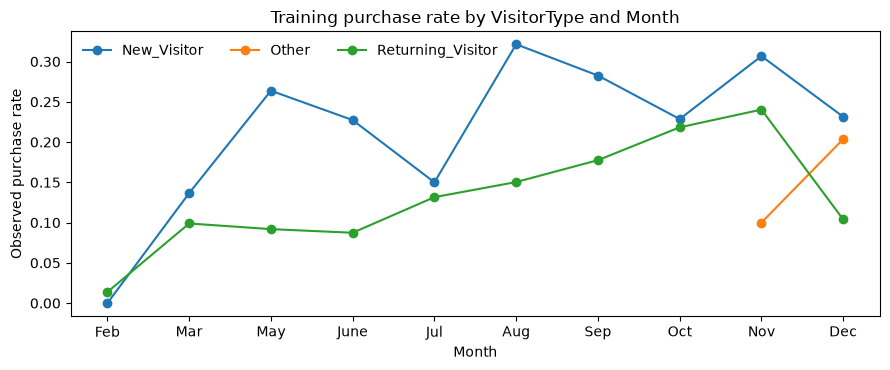

Cells below 50 sessions: 4


,VisitorType,Month,sessions,buyers,purchase_rate
2,New_Visitor,Feb,1,0,0.000
11,Other,Nov,20,2,0.100
4,New_Visitor,June,22,5,0.227
3,New_Visitor,Jul,40,6,0.150


Across supported months (n>=50), purchase-rate ranges by visitor type:


,min,max,count
VisitorType,,,
New_Visitor,0.137,0.321,7
Other,0.204,0.204,1
Returning_Visitor,0.014,0.240,10


New_Visitor: supported-month purchase rates span 13.7%–32.1% across 7 months.
Other: supported-month purchase rates span 20.4%–20.4% across 1 months.
Returning_Visitor: supported-month purchase rates span 1.4%–24.0% across 10 months.
The observed month variation is descriptive and 4 cells are sparse; do not add a VisitorType × Month recipe from this evidence alone.


In [3]:
cross=X.assign(Revenue=y).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index()
display(cross.pivot(index='VisitorType',columns='Month',values='sessions').fillna(0).astype(int)); display(cross.pivot(index='VisitorType',columns='Month',values='purchase_rate').round(3))
fig,ax=plt.subplots(figsize=(9,3.8))
month_order=['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
for v,g in cross.groupby('VisitorType'):
    g=g.assign(Month=pd.Categorical(g.Month,categories=month_order,ordered=True)).sort_values('Month')
    ax.plot(g.Month.astype(str),g.purchase_rate,marker='o',label=v)
ax.set(title='Training purchase rate by VisitorType and Month',xlabel='Month',ylabel='Observed purchase rate'); ax.legend(frameon=False,ncol=3); plt.tight_layout(); plt.show()
small=cross[cross.sessions<50].sort_values('sessions'); print('Cells below 50 sessions:',len(small)); display(small.round(3))
supported=cross[cross.sessions>=50].groupby('VisitorType').purchase_rate.agg(['min','max','count'])
print('Across supported months (n>=50), purchase-rate ranges by visitor type:')
display(supported.round(3))
for visitor,r in supported.iterrows(): print(f"{visitor}: supported-month purchase rates span {r['min']:.1%}–{r['max']:.1%} across {int(r['count'])} months.")
print('The observed month variation is descriptive and 4 cells are sparse; do not add a VisitorType × Month recipe from this evidence alone.')

## 4. Rare nominal levels

**Purpose.** Determine whether extreme rates for TrafficType, Browser or Region may reflect small groups. **Method.** Report every training level's support and buyer rate with a descriptive <50 support flag. **Implication.** Sparse rates are uncertain; this alone does not justify pooling or deletion.

In [4]:
rr=[]
for col in ['TrafficType','Browser','Region']:
    t=X.assign(Revenue=y).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean'))
    for level,r in t.iterrows(): rr.append({'feature':col,'level':str(level),'sessions':int(r.sessions),'buyers':int(r.buyers),'purchase_rate':r.purchase_rate,'support':'<50' if r.sessions<50 else '>=50'})
RARE_LEVELS=pd.DataFrame(rr).sort_values(['feature','sessions','level']); display(RARE_LEVELS.round(4))
sparse=RARE_LEVELS[RARE_LEVELS.support=='<50']
print(f"{len(sparse)} of {len(RARE_LEVELS)} levels have <50 sessions. Among these, observed rates range {sparse.purchase_rate.min():.1%}–{sparse.purchase_rate.max():.1%}; examples at the extremes are highly uncertain. Keep levels nominal; this evidence does not justify arbitrary pooling.")

,feature,level,sessions,buyers,purchase_rate,support
28,Browser,9,1,0,0.0000,<50
30,Browser,11,5,1,0.2000,<50
31,Browser,12,7,3,0.4286,<50
26,Browser,7,36,2,0.0556,<50
32,Browser,13,52,13,0.2500,>=50
22,Browser,3,83,4,0.0482,>=50
27,Browser,8,107,12,0.1121,>=50
29,Browser,10,135,29,0.2148,>=50
25,Browser,6,140,16,0.1143,>=50
24,Browser,5,382,70,0.1832,>=50


13 of 42 levels have <50 sessions. Among these, observed rates range 0.0%–42.9%; examples at the extremes are highly uncertain. Keep levels nominal; this evidence does not justify arbitrary pooling.


## 5. SpecialDay score versus binary presence

**Purpose.** Check whether the score's observed pattern is mainly zero versus positive or varies across score levels. **Method.** Compare training support/rates by exact score and by presence. **Implication.** Baseline remains numeric unless evidence supports a presence representation; associations do not establish score semantics or causality.

,SpecialDay,sessions,buyers,purchase_rate
0,0.0,8850,1466,0.1656
1,0.2,142,13,0.0915
2,0.4,189,9,0.0476
3,0.6,286,26,0.0909
4,0.8,271,6,0.0221
5,1.0,126,6,0.0476


,group,sessions,buyers,rate
0,zero,8850,1466,0.1656
1,positive,1014,60,0.0592


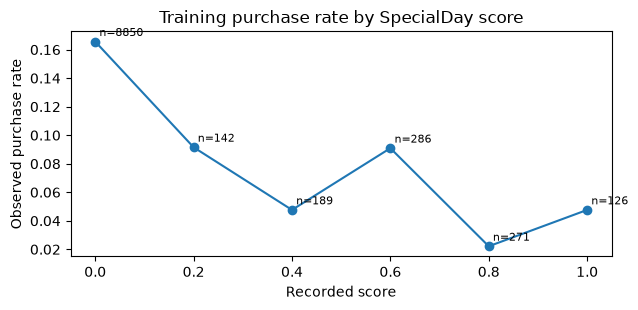

The zero/positive rates are 16.6% and 5.9%; positive-score values are not monotone in rate across their supports. This supports considering presence as a simple representation for the NB revision review, while retaining the numeric baseline.


In [5]:
sp=X.assign(Revenue=y).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index().sort_values('SpecialDay'); display(sp.round(4))
pos=X.SpecialDay>0; special_binary=pd.DataFrame([{'group':'zero','sessions':(~pos).sum(),'buyers':y[~pos].sum(),'rate':y[~pos].mean()},{'group':'positive','sessions':pos.sum(),'buyers':y[pos].sum(),'rate':y[pos].mean()}]); display(special_binary.round(4))
fig,ax=plt.subplots(figsize=(6.5,3.2)); ax.plot(sp.SpecialDay,sp.purchase_rate,marker='o')
for r in sp.itertuples(): ax.annotate(f'n={r.sessions}',(r.SpecialDay,r.purchase_rate),xytext=(3,4),textcoords='offset points',fontsize=8)
ax.set(title='Training purchase rate by SpecialDay score',xlabel='Recorded score',ylabel='Observed purchase rate'); plt.tight_layout(); plt.show()
print(f"The zero/positive rates are {special_binary.loc[0,'rate']:.1%} and {special_binary.loc[1,'rate']:.1%}; positive-score values are not monotone in rate across their supports. This supports considering presence as a simple representation for the NB revision review, while retaining the numeric baseline.")

## 6. Feature availability at a proposed voucher decision time

**Purpose.** Assess whether predictors could be known before a hypothetical mid-session voucher offer. **Method.** Classify all source predictors by what they measure and a cautious timing assessment; the dataset contains no event timestamps. **Implication.** This is a limitation on intervention interpretation, not proof of leakage. No feature is certified for real-time use.

In [6]:
timing=[
('Administrative','Session count of administrative pages','Accumulator may evolve until session end','Unverified'),('Administrative_Duration','Time on administrative pages','Accumulator may evolve until session end','Unverified'),('Informational','Session count of informational pages','Accumulator may evolve until session end','Unverified'),('Informational_Duration','Time on informational pages','Accumulator may evolve until session end','Unverified'),('ProductRelated','Session count of product pages','Accumulator may evolve until session end','Unverified'),('ProductRelated_Duration','Time on product pages','Accumulator may evolve until session end','Unverified'),('BounceRates','Analytics bounce measure','May depend on session completion/processing','Timing unknown'),('ExitRates','Analytics exit measure','May depend on page exit/session completion','Timing unknown'),('PageValues','Analytics page value related to transaction likelihood/value','Could reflect completed-session information','Possible downstream timing; exclude operationally'),('SpecialDay','Calendar proximity score','Calendar-derived','Likely known; unverified'),('Month','Visit month','Calendar-derived','Likely known; unverified'),('OperatingSystems','Operating system category','Potentially observed at arrival','Likely early; unverified'),('Browser','Browser category','Potentially observed at arrival','Likely early; unverified'),('Region','Visitor region category','Geolocation/analytics processing may vary','Unverified'),('TrafficType','Traffic source category','Attribution timing may vary','Unverified'),('VisitorType','New/returning visitor category','May rely on cookies/prior-visit linkage','Unverified'),('Weekend','Weekend indicator','Calendar-derived','Likely known; unverified')]
AVAILABILITY=pd.DataFrame(timing,columns=['predictor','measure','possible timing issue','assessment']); display(AVAILABILITY)
print('PageValues has the clearest possible downstream timing concern; remaining features also require a real decision-time audit.')

,predictor,measure,possible timing issue,assessment
0,Administrative,Session count of administrative pages,Accumulator may evolve until session end,Unverified
1,Administrative_Duration,Time on administrative pages,Accumulator may evolve until session end,Unverified
2,Informational,Session count of informational pages,Accumulator may evolve until session end,Unverified
3,Informational_Duration,Time on informational pages,Accumulator may evolve until session end,Unverified
4,ProductRelated,Session count of product pages,Accumulator may evolve until session end,Unverified
5,ProductRelated_Duration,Time on product pages,Accumulator may evolve until session end,Unverified
6,BounceRates,Analytics bounce measure,May depend on session completion/processing,Timing unknown
7,ExitRates,Analytics exit measure,May depend on page exit/session completion,Timing unknown
8,PageValues,Analytics page value related to transaction li...,Could reflect completed-session information,Possible downstream timing; exclude operationally
9,SpecialDay,Calendar proximity score,Calendar-derived,Likely known; unverified


PageValues has the clearest possible downstream timing concern; remaining features also require a real decision-time audit.


## 7. Compact evidence for conditional model recipes

**Purpose.** Summarize training shape and dependence evidence relevant to the plan's narrow recipes. **Method.** Report numeric skew/zero shares, within-class correlations, representative binned empirical logits and tail plots. **Implication.** These marginal diagnostics can motivate recipes for independent review; they do not prove conditional linearity, Gaussianity, equal covariance or improved AUC.

,skew,zero_share,median,p95
Administrative,1.9668,0.4671,1.0000,9.0000
Administrative_Duration,5.6787,0.4771,8.0000,348.5253
Informational,4.1424,0.7854,0.0000,3.0000
Informational_Duration,7.7018,0.8047,0.0000,194.9250
ProductRelated,4.3718,0.0027,18.0000,108.0000
ProductRelated_Duration,8.0091,0.0620,600.5367,4232.5228
BounceRates,2.9241,0.4484,0.0031,0.2000
ExitRates,2.1295,0.0062,0.0252,0.2000
PageValues,6.1867,0.7777,0.0000,39.1639
SpecialDay,3.2609,0.8972,0.0000,0.6000


class 0 absolute correlation
BounceRates    ExitRates                                    0.914923
ProductRelated ProductRelated_Duration                      0.838882
Informational  Informational_Duration                       0.632216
Administrative Administrative_Duration                      0.585541
               ProductRelated                               0.433914
Informational  ProductRelated_Duration                      0.386907

class 1 absolute correlation
ProductRelated ProductRelated_Duration                      0.895908
BounceRates    ExitRates                                    0.723380
Informational  Informational_Duration                       0.633768
Administrative Administrative_Duration                      0.588880
               ProductRelated                               0.404739
               ProductRelated_Duration                      0.383842

Binned marginal empirical logit, zero retained as one stratum: Informational


,bin,n,mean_x,buyers,rate,empirical_logit
4,zero,7747,0.0000,1030,0.1330,-1.8747
0,"(0.999, 2.0]",1435,1.4125,318,0.2216,-1.2552
1,"(2.0, 3.0]",299,3.0000,76,0.2542,-1.0721
2,"(3.0, 4.0]",179,4.0000,45,0.2514,-1.0839
3,"(4.0, 24.0]",204,6.5588,57,0.2794,-0.9420


...

,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,4706,0.0000,424,0.0901,-2.3114
0,"(1.332, 20.0]",660,11.0791,109,0.1652,-1.6167
3,"(20.0, 39.325]",630,29.6943,135,0.2143,-1.2966
5,"(39.325, 60.792]",644,49.8278,136,0.2112,-1.3151
6,"(60.792, 87.725]",645,73.5512,142,0.2202,-1.2622
7,"(87.725, 123.05]",645,103.9547,123,0.1907,-1.4424
1,"(123.05, 181.763]",644,150.9107,137,0.2127,-1.3059
2,"(181.763, 298.614]",645,231.2798,157,0.2434,-1.1319
4,"(298.614, 3398.75]",645,592.8679,163,0.2527,-1.0822


Binned marginal empirical logit, zero retained as one stratum: ProductRelated_Duration


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,612,0.0000,8,0.0131,-4.2643
0,"(0.499, 105.344]",1157,52.2660,58,0.0501,-2.9336
2,"(105.344, 241.0]",1157,169.8017,68,0.0588,-2.7666
4,"(241.0, 428.038]",1156,327.7485,141,0.1220,-1.9708
6,"(428.038, 673.017]",1156,544.9692,200,0.1730,-1.5625
7,"(673.017, 1029.532]",1156,833.9943,245,0.2119,-1.3118
1,"(1029.532, 1564.04]",1157,1270.9825,248,0.2143,-1.2975
3,"(1564.04, 2593.783]",1156,2003.6607,238,0.2059,-1.3484
5,"(2593.783, 63973.522]",1157,4915.6784,320,0.2766,-0.9605


Binned marginal empirical logit, zero retained as one stratum: BounceRates


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,4423,0.0000,848,0.1917,-1.4384
0,"(-0.0009273, 0.00385]",689,0.0023,166,0.2409,-1.1455
1,"(0.00385, 0.00656]",672,0.0051,152,0.2262,-1.2276
2,"(0.00656, 0.01]",706,0.0082,133,0.1884,-1.4577
3,"(0.01, 0.0148]",659,0.0124,95,0.1442,-1.7768
4,"(0.0148, 0.0222]",706,0.0185,70,0.0992,-2.2004
5,"(0.0222, 0.0389]",649,0.0296,38,0.0586,-2.7653
6,"(0.0389, 0.1]",697,0.0619,21,0.0301,-3.4489
7,"(0.1, 0.2]",663,0.1909,3,0.0045,-5.2402


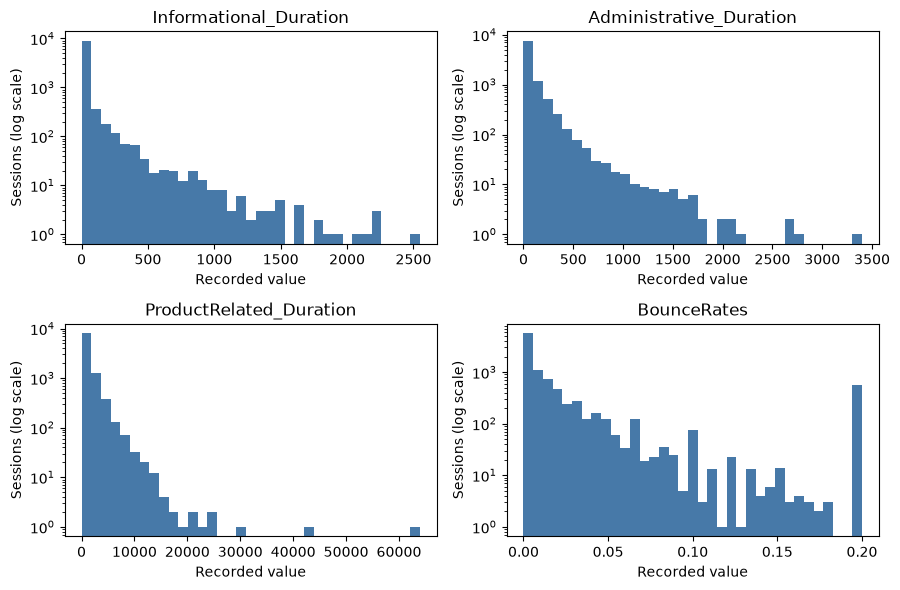

Activity fields with |skew|>2: ['Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration']
Activity fields with training zero share >=50%: ['Informational', 'Informational_Duration']
The training evidence shows long right tails across five of six activity fields and high zero prevalence for both informational measures; this supports evaluating the plan’s fixed log1p form and fold-fitted indicators for those high-zero fields. Strong within-class dependence (notably BounceRates/ExitRates and ProductRelated/ProductRelated_Duration) challenges Naive Bayes conditional independence. The observed class-specific correlation differences suggest possible covariance heterogeneity, but these selected pairs do not establish unequal full covariance matrices. Long tails and mixed numeric/nominal inputs challenge LDA’s multivariate Gaussian ideal; correlated predictors alone do not violate LDA’s covariance assumption. No model has been fitted or 

In [7]:
allnum=NUMERIC+['Weekend']; shape=pd.DataFrame({'skew':X[allnum].skew(),'zero_share':X[allnum].eq(0).mean(),'median':X[allnum].median(),'p95':X[allnum].quantile(.95)})
display(shape.round(4))
for cls in [0,1]:
    cor=X.loc[y==cls,allnum].corr().abs(); pairs=cor.where(np.triu(np.ones(cor.shape),1).astype(bool)).stack().sort_values(ascending=False).head(6); display(pairs.rename(f'class {cls} absolute correlation').to_frame())
def elogit(col):
    z=pd.DataFrame({'x':X[col],'buyer':y}); z['bin']='zero'
    positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],8,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['bin']=out['bin'].astype(str)
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5)); return out.sort_values('mean_x')
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration','ProductRelated_Duration','BounceRates']:
    print('Binned marginal empirical logit, zero retained as one stratum:',col); display(elogit(col).round(4))
fig,axs=plt.subplots(2,2,figsize=(9,6))
for ax,col in zip(axs.flat,['Informational_Duration','Administrative_Duration','ProductRelated_Duration','BounceRates']):
    ax.hist(X[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Sessions (log scale)')
plt.tight_layout(); plt.show()
activity=shape.loc[ACTIVITY]
print('Activity fields with |skew|>2:',activity.index[activity['skew'].abs()>2].tolist())
print('Activity fields with training zero share >=50%:',activity.index[activity['zero_share']>=.50].tolist())
print('The training evidence shows long right tails across five of six activity fields and high zero prevalence for both informational measures; this supports evaluating the plan’s fixed log1p form and fold-fitted indicators for those high-zero fields. Strong within-class dependence (notably BounceRates/ExitRates and ProductRelated/ProductRelated_Duration) challenges Naive Bayes conditional independence. The observed class-specific correlation differences suggest possible covariance heterogeneity, but these selected pairs do not establish unequal full covariance matrices. Long tails and mixed numeric/nominal inputs challenge LDA’s multivariate Gaussian ideal; correlated predictors alone do not violate LDA’s covariance assumption. No model has been fitted or compared.')